## Summary

We present a reusable, cloud-scalable pipeline that pairs Cellpose-SAM segmentation with on-demand GPU compute (Modal and S3) for single-cell phenotyping of high-content microscopy, demonstrated on a two-species yeast panel (*S. cerevisiae* versus *S. pombe*).

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

High-content microscopy can generate more images than a single workstation can process in a reasonable amount of time. Segmentation is the computationally intensive step, but arriving at a biological answer often also involves transferring large volumes of image data, provisioning GPUs, running sophisticated segmentation algorithms, and collecting standardized per-cell measurements. In this pub, we present a worked example that handles this entire workflow, pairing Cellpose-SAM [@pachitariu2025cellpose] with on-demand compute to scale segmentation across cloud GPUs. This shortens the path from imaging to biological interpretation and gives readers a pattern they can adapt to their own data rather than assemble from scratch. On a two-species yeast panel, we show:

1. Cellpose-SAM, combined with cloud GPU compute, can efficiently scale single-cell phenotyping across large microscopy datasets.
2. The phenotyping outputs derived from the segmentation resolve gross morphological differences between populations.

This pub is aimed at researchers developing high-throughput microscopy workflows or deciding how to scale segmentation and phenotyping. The analysis that follows runs on a dataset of two yeast species (*S. cerevisiae* and *S. pombe*), which is useful for validating the pipeline rather than a source of new biological conclusions. The workflow isn't yeast-specific — the same steps of file I/O, segmentation, parallel execution, and per-cell measurement carry over to other images, though it's best suited to imaging individual cells, such as unicellular organisms or dissociated cell populations, where cells can be segmented cleanly. For background on the tools we build on, see the Cellpose-SAM literature [@pachitariu2025cellpose] and the Modal documentation.

## The pipeline

### How the pieces fit together

:::{.callout-note title="Draft figure" collapse="false"}
A designed hero figure (in progress with Audrey) will replace the schematic below. The Mermaid diagram is a functional stand-in that captures the intended flow.
:::

The workflow is a straight line from raw images to per-cell measurements, with one key property: the segmentation step is identical whether it runs on one machine or hundreds of GPU containers. Scale is a deployment choice, not a code rewrite.

```{mermaid}
flowchart LR
  A["Brightfield ND2s<br/>datasets/&lt;id&gt;/raw/"] --> B["File I/O + preprocessing<br/>arcadia-microscopy-tools"]
  B --> C["Segmentation<br/>Cellpose-SAM → label masks"]
  C --> D{"Scale-out<br/>one worker per image"}
  D --> E["Derived artifacts<br/>masks · overlays · measurements"]
  E --> F["Analysis<br/>pooled per-cell morphology"]
  P["Plate map<br/>well → strain"] --> F
```

1. **Input:** brightfield ND2s in object storage, organized as `datasets/<id>/raw/`, with a plate map linking wells to strains.
2. **File I/O and preprocessing:** `arcadia-microscopy-tools` handles ND2 reading, channel and pixel-size metadata, a difference-of-Gaussians bandpass, and percentile rescaling.
3. **Segmentation:** Cellpose-SAM produces label masks; cells at the edge of the field of view are dropped.
4. **Scale-out:** one worker per image is fanned across on-demand GPU containers, each reading from and writing to shared cloud storage.
5. **Outputs (`derived/`):** label-mask TIFFs, outline-overlay JPGs for QC, and per-cell measurement CSVs (regionprops, in microns where the pixel size is known).
6. **Analysis:** pooled per-cell measurements joined to the plate map for morphology comparisons across strains.

### A two-species yeast panel

To validate the pipeline, we collected brightfield images of two diploid yeasts chosen for visually distinct morphologies — ovoid budding yeast (*S. cerevisiae* BY4743) and rod-shaped fission yeast (*S. pombe* SP286) — across 16 wells of a 96-well plate. We imaged each well at four fields in a 2×2 grid, yielding 64 ND2 files. The plate map (@tbl-plate-map) links each well to genus, species, strain, and ploidy. Culture, acquisition settings, and software versions are in @sec-methods.

At 64 images, the plate is big enough to show cloud GPU scaling in action but small enough to run and inspect end to end. And with eight replicate wells per species, we can work at the well level — comparing per-well medians across the 16 wells rather than treating every cell as an independent measurement (@tbl-features).

| Species | Strain | Wells |
| --- | --- | --- |
| *S. cerevisiae* | `BY4743` | K01–K04, L01–L04 |
| *S. pombe* | `SP286` | K05–K08, L05–L08 |

: Plate map for the two-species panel {#tbl-plate-map}

The metadata from a representative ND2 file (well K01; @tbl-nd2-meta) records the optics and pixel size used across the plate. We use that pixel size to convert the downstream morphology measurements to micrometers.

In [1]:
# | code-fold: true
# | code-summary: "Code to load the example ND2 and extract metadata"
# | label: tbl-nd2-meta
# | tbl-cap: "Acquisition metadata from a representative brightfield ND2 file."

import subprocess
from pathlib import Path

import pandas as pd
from arcadia_microscopy_tools.nikon import parse_nd2

DATASET_ID = "20260611_141152_330"
EXAMPLE_ND2 = "WellK01_PointK01_0000_Channelbrightfield_Seq0000.nd2"
RAW_DIR = Path("scratch/sample_data") / DATASET_ID / "raw"
nd2_path = RAW_DIR / EXAMPLE_ND2

if not nd2_path.exists():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    src = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/raw/{EXAMPLE_ND2}"
    try:
        subprocess.run(["aws", "s3", "cp", src, str(nd2_path)], check=True, capture_output=True)
    except (FileNotFoundError, subprocess.CalledProcessError):
        from analysis.sample_data import fetch_sample_nd2s

        nd2_path = fetch_sample_nd2s(DATASET_ID, RAW_DIR, limit=1)[0]

meta = parse_nd2(nd2_path)
cm = meta.channel_metadata_list[0]

pd.DataFrame.from_dict(
    {
        "file": nd2_path.name,
        "channel": cm.channel.name,
        "objective": cm.optics.objective,
        "magnification": cm.optics.magnification,
        "NA": cm.optics.numerical_aperture,
        "pixel_size_um": cm.resolution.xy_step_um,
        "exposure_s": cm.acquisition.exposure_time_s,
    },
    orient="index",
    columns=["value"],
)

,value
file,WellK01_PointK01_0000_Channelbrightfield_Seq00...
channel,BRIGHTFIELD
objective,PLAN APO λD 40x OFN25 DIC N2
magnification,40
NA,0.95
pixel_size_um,0.1625
exposure_s,0.01


### Single-cell segmentation at scale

This section covers the main step of the pipeline: segmenting the images and measuring the cells, across the whole plate. Each image is processed the same way regardless of where the computation runs, so we describe that per-image work first and then the two ways of running it.

For each of the 64 brightfield fields, the pipeline applies a difference-of-Gaussians bandpass (sigmas 1.6 and 16 px), contrast-stretches the result, and runs Cellpose-SAM [@pachitariu2025cellpose], through `arcadia-microscopy-tools`, to produce a label mask. Cells touching the edge of the field are removed before measurement, since a truncated outline would bias area and shape. The remaining cells are measured with scikit-image regionprops and converted to micrometers using the pixel size recorded in the ND2. The mask is also drawn as a yellow outline over the brightfield, which we use for visual QC. For each image, the pipeline writes three artifacts under the dataset's `derived/` prefix: a label-mask TIFF (`masks/`), an overlay JPG (`overlays/`), and a per-cell measurement CSV (`measurements/`).

The same code runs in one of two modes, chosen automatically so the notebook works with or without our cloud infrastructure. Both modes produce the same artifacts, and rerunning the notebook reproduces them.

::: {.panel-tabset}

#### Scaled execution (Modal + S3)

With our cloud infrastructure, each ND2 is processed by its own GPU worker [@modal]. The worker reads the file from S3, runs Cellpose-SAM, measures the cells, renders the overlay, and writes the three artifacts back to the bucket. Because the files are independent, the plate is processed in parallel.

#### Local execution (no cloud account required)

Without a cloud account, the same Cellpose-SAM code runs locally, on CPU by default, and writes the same three artifacts to a local `derived/` folder. The ND2 files download from the public Zenodo archive once the record id is set (`CSCP_ZENODO_RECORD_ID` or `ZENODO_RECORD_ID`); until then the local path raises an error naming those variables. On CPU, the plate is processed one image at a time, so it's slower than the GPU version.

:::

The plate is run by `run_demo`, which returns the same result object in either mode and prints a summary of how many images finished, how many failed, and the wall-clock time. Two parameters affect the segmentation: we set `diameter=30` (pixels), Cellpose-SAM's usual default cell size, and `cellprob_threshold=3.0`, which is stricter than the library default of 0.0 and is the cutoff we found suppressed debris on these brightfield yeast fields. Both our values and the library defaults are in @tbl-segment-config.

::: {.callout-note title="Choosing a backend and rerunning the segmentation" collapse="true"}
Set `CSCP_FORCE_LOCAL=1` to force the local path, or pass `backend="modal"` / `backend="local"` to `run_demo`. Details live in the [setup guide](pages/SETUP.qmd).

If you rerun this notebook locally, note that segmenting the full plate on CPU is very slow. Set `LIMIT` to a small number to process only a few images; the rest of the notebook still runs from the pre-computed outputs, so you don't need to segment the whole plate to reproduce the downstream results.
:::

In [2]:
# | code-fold: true
# | code-summary: "Code for processing the full plate"

import time

from analysis.runner import run_demo

# None processes every ND2. Both backends run the full plate; local CPU is sequential.
LIMIT = None
BACKEND = "auto"
CELL_DIAMETER = 30  # pixels
CELLPROB_THRESHOLD = 0.0

started = time.time()
run = run_demo(
    DATASET_ID,
    limit=LIMIT,
    backend=BACKEND,
    diameter=CELL_DIAMETER,
    cellprob_threshold=CELLPROB_THRESHOLD,
)
elapsed = time.time() - started

if run.backend == "modal":
    print(f"[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/{run.output_prefix}/")
else:
    print(f"[local] Wrote artifacts to {run.output_prefix}")
print(f"Segmented {len(run.results)} image(s), {len(run.failures)} failure(s) in {elapsed:.1f}s.")

Segmenting: 100%|██████████| 64/64 [02:10<00:00,  2.04s/img, 974 cells · 111216 total] 

[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/datasets/20260611_141152_330/derived/
Segmented 64 image(s), 0 failure(s) in 139.5s.


### How the full plate scales

The segmentation described above processes the full plate once. To see how that holds up as the plate grows, we ran the same 64 images several more times and recorded wall-clock time and cost (@tbl-benchmark): Modal L4 GPUs across a range of worker counts, plus a single full-plate run on a local Apple M3 Max GPU. Throughput is images per wall-clock minute.

| Path | Images | Workers | Wall clock | Cost | Throughput |
| --- | --- | --- | --- | --- | --- |
| Cloud | 64 | 1 | 1,609 s (27 min) | $0.31 | 2.4 img/min |
| Cloud | 64 | 4 | 376 s (6.3 min) | $0.34 | 10 img/min |
| Cloud | 64 | 16 | 140 s (2.3 min) | $0.41 | 27 img/min |
| Cloud | 64 | 64 | 86 (1.4 min) | $0.83 | 45 img/min |
| Local | 64 | 1 | 1,964 s (32.7 min) | — | 2.0 img/min |

: Wall clock and cost to segment the 64-image plate on cloud (Modal, L4) and local (Apple M3 Max) GPUs {#tbl-benchmark}

Adding workers helps, but with diminishing returns. Wall clock drops from 27 min on a single L4 to 2.3 min on 16 workers, then only to 1.4 min on 64. On one worker, the images take 1,515 s of compute against 1,609 s of wall clock, so only about 95 s is startup and orchestration. On 64 workers, the median per-image time climbs from 22 s to 34 s as the shared GPU fleet gets busier, and the total wall clock (86 s) is roughly two and a half times that median — at that point the plate is waiting on cold starts and the slowest few images rather than on compute. Cost follows the same pattern: it stays near $0.30–$0.40 from 1 to 16 workers and rises to $0.83 at 64, where the extra parallelism is mostly paying for GPUs sitting idle while the slowest image finishes.

We default `max_containers` to 16, which we find is a good trade-off: it processes the plate in just over 2 min at close to the lowest cost, before the diminishing returns at higher worker counts set in. It also stays within our organization's cap of 100 concurrent GPUs on Modal's shared fleet, so it's a considerate ceiling as well as an efficient one. For comparison, the local M3 Max run (roughly 30 min) lands in the same range as a single cloud L4 — fine for a handful of images, slow for a full plate.

The scaled path is a container that reads from and writes to object storage, so the same pattern ports to AWS Batch, Slurm, or any other queue that can run a GPU container against a bucket. Modal isn't required to use the method — only to use this particular scheduler. None of these runs recorded a failure, but if a worker were to fail, `run.failures` records the image and the error, and the rest of the plate continues. The pipeline doesn't retry on its own, so we would manually re-run the missing files after debugging.

## Results

### Visual inspection

The pipeline writes a segmentation overlay for each image, with cell boundaries drawn in yellow on the brightfield. @fig-overlays shows one 600 × 600 cropped field of view per species: wells K01 and K05, the first well of each species on the plate map (@tbl-plate-map). Good segmentation traces each cell tightly, without merging neighbors or splitting one cell in two. Cells touching the edge of the field are dropped, since a truncated outline would bias their measurements.

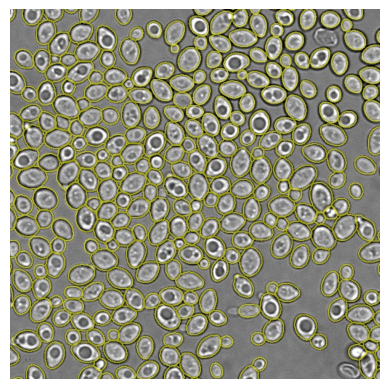

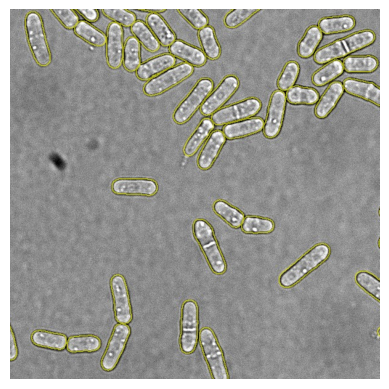

In [3]:
# | echo: false
# | label: fig-overlays
# | layout-ncol: 2
# | fig-cap: "Cellpose-SAM outlines on brightfield. Each panel is a 600 × 600 crop from the center of one field."
# | fig-subcap:
# |   - "*S. cerevisiae* BY4743, well K01"
# |   - "*S. pombe* SP286, well K05"
# | fig-alt:
# |   - "Center crop of a brightfield field of ovoid budding yeast with yellow cell outlines."
# |   - "Center crop of a brightfield field of rod-shaped fission yeast with yellow cell outlines."

import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

QC_WELLS = ("K01", "K05")
QC_CROP = 600


def _well(name: str) -> str | None:
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


def _from_run(well: str) -> Path | None:
    for summary in run.results:
        path = summary.get("local_overlay")
        if not path:
            continue
        path = Path(path)
        name = str(summary.get("input", ""))
        if path.exists() and _well(name) == well:
            return path
    return None


def _from_derived(well: str) -> Path | None:
    dest_dir = Path("scratch/segmentation_results")
    dest_dir.mkdir(parents=True, exist_ok=True)
    for path in sorted(dest_dir.glob("*_overlay.jpg")):
        if _well(path.name) == well:
            return path
    prefix = f"s3://cloud-scaled-cell-phenotyping/datasets/{DATASET_ID}/derived/overlays/"
    try:
        listed = subprocess.run(
            ["aws", "s3", "ls", prefix], check=True, capture_output=True, text=True
        )
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None
    for line in listed.stdout.splitlines():
        name = line.split()[-1] if line.split() else ""
        if not (name.endswith("_overlay.jpg") and _well(name) == well):
            continue
        dest = dest_dir / name
        try:
            subprocess.run(
                ["aws", "s3", "cp", prefix + name, str(dest)],
                check=True,
                capture_output=True,
            )
        except (FileNotFoundError, subprocess.CalledProcessError):
            return None
        return dest if dest.exists() else None
    return None


def _center_crop(image: np.ndarray, size: int) -> np.ndarray:
    height, width = image.shape[:2]
    size = min(size, height, width)
    y0 = (height - size) // 2
    x0 = (width - size) // 2
    return image[y0 : y0 + size, x0 : x0 + size]


for well in QC_WELLS:
    overlay = _from_run(well) or _from_derived(well)
    if overlay is None:
        raise FileNotFoundError(
            f"No overlay for well {well}. Rerun the segmentation above or copy "
            f"precomputed overlays from the dataset's derived/ prefix."
        )
    fig, ax = plt.subplots()
    ax.imshow(_center_crop(plt.imread(overlay), QC_CROP))
    ax.set_axis_off()
    plt.show()

### Per-cell phenotyping outputs

Alongside the masks and overlays, the pipeline turns each segmented cell into a row of shape measurements — area, eccentricity, axis lengths, and related features — using scikit-image regionprops [@vanderwalt2014scikit], converted to micrometers wherever the pixel size is known (@tbl-cells). Pooling these tables across all 64 images and joining them to the plate map attaches a species label to every cell, which gives us the single-cell dataset for the analysis that follows.

The segmentation workers write these tables to shared storage, and the analysis reads them back from there — from S3 or the public Zenodo archive — so the downstream results reproduce without rerunning segmentation.

The code below pools the per-image measurement tables into one table and joins it to the plate map, so each row is a single cell with its shape features (in micrometers) and species label. This pooled table is the dataset for the rest of the analysis.

::: {.callout-note title="Where the measurements load from" collapse="true"}
By default (MEASUREMENTS_SOURCE = "auto"), the analysis loads the published table from S3 or Zenodo. If the Zenodo archive isn't configured, the loader raises an error naming CSCP_ZENODO_RECORD_ID (or ZENODO_RECORD_ID); set one of those once the record is published.
:::

In [4]:
# | echo: false
# | label: tbl-cells
# | tbl-cap: "Pooled per-cell measurements joined to the plate map (first five rows)."

import re
from pathlib import Path

import pandas as pd
from analysis.measurements import load_measurements

# "auto" loads the published full-plate table from S3 or Zenodo;
# "run" uses the measurements returned by the segmentation above.
MEASUREMENTS_SOURCE = "run"  # "run" | "auto" | "modal" | "zenodo"

if MEASUREMENTS_SOURCE == "run":
    measurements = run.measurements.copy()
else:
    measurements = load_measurements(DATASET_ID, source=MEASUREMENTS_SOURCE)


def _find_plate_map() -> Path:
    for candidate in (Path("plate-map.csv"), Path("../plate-map.csv")):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("plate-map.csv not found next to the notebook or its parent.")


plate_map = pd.read_csv(_find_plate_map())


def well_from_name(name: str) -> str | None:
    """Pull a plate-well token (e.g. 'K01') from an NIS image name."""
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


measurements["well"] = measurements["image"].map(well_from_name)
labeled = measurements.merge(plate_map[["well", "species", "strain"]], on="well", how="left")

n_unmapped = int(labeled["species"].isna().sum())
if n_unmapped:
    print(
        f"Warning: {n_unmapped} cell(s) had no species match; check well_from_name vs. your filenames."
    )
print(f"{len(labeled)} cells across {labeled['species'].nunique()} species.")
labeled.head()

111216 cells across 2 species.


,image,label,area_um2,area_convex_um2,perimeter_um,eccentricity,solidity,axis_major_length_um,axis_minor_length_um,orientation,...,volume_um3,centroid_y,centroid_x,intensity_mean_brightfield,intensity_max_brightfield,intensity_min_brightfield,intensity_std_brightfield,well,species,strain
0,WellK01_PointK01_0000_Channelbrightfield_Seq0000,1,3.247969,3.327188,6.848097,0.833476,0.976190,2.796265,1.545093,1.557885,...,3.495314,4.390244,156.178862,8360.943089,12074.0,4180.0,1878.051340,K01,cerevisiae,BY4743
1,WellK01_PointK01_0000_Channelbrightfield_Seq0000,2,2.112500,2.693438,7.850978,0.987773,0.784314,4.305462,0.671226,-1.566048,...,1.015679,2.587500,603.537500,7888.650000,8531.0,7178.0,318.510247,K01,cerevisiae,BY4743
2,WellK01_PointK01_0000_Channelbrightfield_Seq0000,3,2.851875,2.931094,7.077907,0.922667,0.972973,3.147329,1.213606,1.557823,...,2.427147,3.537037,1195.759259,7629.027778,10633.0,4981.0,1402.505400,K01,cerevisiae,BY4743
3,WellK01_PointK01_0000_Channelbrightfield_Seq0000,4,15.025156,15.394844,14.139481,0.587677,0.975986,4.867268,3.938085,-0.026246,...,39.523367,15.298770,1928.912127,7511.982425,13169.0,3130.0,2136.657715,K01,cerevisiae,BY4743
4,WellK01_PointK01_0000_Channelbrightfield_Seq0000,5,6.548750,6.997656,9.633694,0.658290,0.935849,3.337724,2.512520,1.227397,...,11.032353,9.193548,409.491935,7759.399194,11136.0,4800.0,1387.045749,K01,cerevisiae,BY4743


### Shape alone separates the two species

The per-cell measurements are the pipeline's actual product, so the fair test is whether they support the analysis we would run next. Given nothing but per-cell shape, the two yeasts should separate: *S. cerevisiae* is an ovoid budding yeast and *S. pombe* is a rod. A pipeline that failed this test would not be worth scaling.

Two steps follow. First comes the joint distribution of the two features that should carry most of the signal, cell area and eccentricity (@fig-area-ecc). Then every shape feature is ranked by how well it separates the species on its own (@tbl-features).

Before those plots, we gate on cell area. Segmentation returns some objects that are not single cells: fragments and debris at the small end, and clumps that Cellpose resolved as a single mask at the large end (the largest object in the full-plate table is about 1,270 μm², 50 times the median *S. cerevisiae* cell). We keep objects between 5 and 100 μm², an area-equivalent circular diameter of 2.5–11.3 μm, which brackets a plausible single yeast cell. The gate is deliberately loose: it drops 1.34% of objects and is not tuned to flatter the analysis.

In [5]:
# | code-fold: true
# | code-summary: "Code to set up the analysis and gate on cell area"

import arcadia_pycolor as apc
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

apc.plotly.setup()

GROUP_COL = "species"
REFERENCE = "cerevisiae"  # the species the others are compared against
POSITIVE = "pombe"  # the "positive" class for AUC
AREA_COL = "area_um2" if "area_um2" in labeled.columns else "area"
AREA_LABEL = "cell area (μm²)" if AREA_COL == "area_um2" else "cell area (px)"

# Plausible-single-cell gate. 5–100 μm² is an area-equivalent circular diameter of
# 2.5–11.3 μm: below it, debris and partial masks; above it, merged clumps.
MIN_AREA_UM2 = 5.0
MAX_AREA_UM2 = 100.0

measured = labeled.dropna(subset=[GROUP_COL, AREA_COL])
# The gate is written in μm², so it only applies when the pixel size was known.
in_gate = (
    measured[AREA_COL].between(MIN_AREA_UM2, MAX_AREA_UM2)
    if AREA_COL == "area_um2"
    else pd.Series(True, index=measured.index)
)
analysis_df = measured.loc[in_gate].copy()

present = list(analysis_df[GROUP_COL].unique())
groups = ([REFERENCE] if REFERENCE in present else []) + sorted(
    g for g in present if g != REFERENCE
)

# Italicized "S. pombe"-style labels and a stable color per species, from the plate map.
genus_by_species = plate_map.drop_duplicates(GROUP_COL).set_index(GROUP_COL)["genus"]
DISPLAY = {species: f"<i>{genus_by_species[species][0]}. {species}</i>" for species in groups}
COLORS = dict(
    zip(groups, [apc.aegean.hex_code, apc.amber.hex_code, apc.seaweed.hex_code], strict=False)
)

n_dropped = int((~in_gate).sum())
print(
    f"{len(analysis_df):,} of {len(measured):,} cells pass the "
    f"{MIN_AREA_UM2:g}–{MAX_AREA_UM2:g} μm² gate "
    f"({n_dropped:,} dropped, {n_dropped / len(measured):.2%})."
)
print(
    f"{len(groups)} species across {analysis_df['well'].nunique()} well(s) and "
    f"{analysis_df['image'].nunique()} image(s): {', '.join(groups)}"
)

110,497 of 111,216 cells pass the 5–100 μm² gate (719 dropped, 0.65%).
2 species across 16 well(s) and 64 image(s): cerevisiae, pombe


In [6]:
# | code-fold: true
# | code-summary: "Code for the area-vs-eccentricity figure"
# | label: fig-area-ecc
# | fig-cap: "Joint distribution of cell area and eccentricity, with marginal box plots. Scatter points are a random subsample of 5,000 cells per species; boxes use every cell that passed the area gate."
# | fig-alt: "Scatter plot of cell area versus eccentricity with two largely non-overlapping clouds for budding yeast and fission yeast, and box plots along each axis."

# Every cell is used for the marginal boxes; the scatter shows a random subsample per
# species, since 112,000 overplotted markers read as two solid blobs (and bloat the page).
POINTS_PER_SPECIES = 5000
rng = np.random.default_rng(0)


def box_stats(values):
    """Quartiles and Tukey fences for a Plotly box trace built from precomputed statistics."""
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    iqr = q3 - q1
    return dict(
        q1=[q1],
        median=[median],
        q3=[q3],
        lowerfence=[max(values.min(), q1 - 1.5 * iqr)],
        upperfence=[min(values.max(), q3 + 1.5 * iqr)],
        mean=[values.mean()],
    )


fig = make_subplots(
    rows=2,
    cols=2,
    column_widths=[0.85, 0.15],
    row_heights=[0.15, 0.85],
    shared_xaxes=True,
    shared_yaxes=True,
    horizontal_spacing=0.02,
    vertical_spacing=0.02,
)

for species in groups:
    cells = analysis_df[analysis_df[GROUP_COL] == species]
    color = COLORS[species]

    shown = cells.iloc[
        rng.choice(len(cells), size=min(POINTS_PER_SPECIES, len(cells)), replace=False)
    ]
    fig.add_trace(
        go.Scattergl(
            x=shown[AREA_COL],
            y=shown["eccentricity"],
            mode="markers",
            showlegend=False,
            marker=dict(color=color, size=3, opacity=0.4, line=dict(width=0)),
            hovertemplate=f"{species}<br>area %{{x:.1f}} μm²<br>ecc. %{{y:.2f}}<extra></extra>",
        ),
        row=2,
        col=1,
    )
    # A legend-only proxy, so the key shows a full-size, full-opacity marker.
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            name=f"{DISPLAY[species]}  (n = {len(cells):,})",
            marker=dict(color=color, size=9),
        ),
        row=2,
        col=1,
    )

    box_kwargs = dict(
        showlegend=False,
        fillcolor=color,
        line=dict(color=apc.charcoal.hex_code, width=1),
        width=0.45,
        hoverinfo="skip",
    )
    fig.add_trace(
        go.Box(**box_stats(cells[AREA_COL].to_numpy()), y=[species], orientation="h", **box_kwargs),
        row=1,
        col=1,
    )
    fig.add_trace(
        go.Box(**box_stats(cells["eccentricity"].to_numpy()), x=[species], **box_kwargs),
        row=2,
        col=2,
    )

fig.update_xaxes(title_text=AREA_LABEL, range=[0, MAX_AREA_UM2], row=2, col=1)
fig.update_yaxes(title_text="eccentricity", range=[0, 1.02], row=2, col=1)
for row, col in ((1, 1), (2, 2)):  # the marginals borrow their scale from the scatter
    fig.update_xaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)
    fig.update_yaxes(showticklabels=False, ticks="", showline=False, row=row, col=col)

fig.update_layout(
    width=720,
    height=560,
    title="Area and eccentricity split the panel into two populations",
    legend=dict(
        x=0.99, y=0.03, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.75)"
    ),
)
apc.plotly.style_plot(fig, monospaced_axes="xy", row=2, col=1)
fig.show()

The two clouds in @fig-area-ecc barely touch. *S. pombe* traces a tight arc, which is what fission yeast morphology predicts: it grows by extending its tips at roughly constant width, so a cell gets larger and more elongated at the same time, and area and eccentricity rise together over the cell cycle. *S. cerevisiae* instead fills a broad, rounder cloud with a tail toward small area and low eccentricity: mostly small buds. The marginal boxes show where the separation actually comes from. The area distributions overlap substantially, since a large budding yeast is the size of a small fission yeast, while the eccentricity distributions hardly overlap at all.

### Ranking every shape feature

Area and eccentricity are two of the nine shape features the pipeline reports. To rank all of them, we use the area under the receiver operating characteristic (ROC) curve for each feature on its own: the probability that a randomly chosen *S. pombe* cell scores higher than a randomly chosen *S. cerevisiae* cell. An AUC of 0.5 means the feature is useless and 1.0 means the two distributions do not overlap at all. It is a rank statistic, so the long tails in these distributions do not distort it.

@tbl-features also reports a two-sided Mann–Whitney *$p$*-value on the well-level medians, not on the individual cells. The null hypothesis is that the well-median distributions of a given feature are the same in the two species. Cells from the same well share a field of view, a focus plane, and an illumination profile, so a test across all 113,454 cells (111,929 after the gate) would treat those shared conditions as independent observations and return *$p$* ≈ 0 for every feature. The table instead compares 16 well medians, eight per species. With eight versus eight, the smallest two-sided *$p$*-value is 1.6 × 10⁻⁴, and several features reach it because their well medians do not overlap. Those wells are technical replicates, so the test measures consistency across wells rather than a difference between the species.

In [7]:
# | code-fold: true
# | code-summary: "Code to rank shape features by how well each one separates the species"
# | label: tbl-features
# | tbl-cap: "Shape features ranked by how well each one separates the two species (AUC on cells; two-sided Mann–Whitney test on well medians)."

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

# Shape only. Orientation is an arbitrary lab-frame angle, the centroids are positions, and
# the brightfield intensities describe illumination as much as they describe the cell.
FEATURES = {
    "area_um2": "area (μm²)",
    "area_convex_um2": "convex area (μm²)",
    "perimeter_um": "perimeter (μm)",
    "axis_major_length_um": "major axis (μm)",
    "axis_minor_length_um": "minor axis (μm)",
    "eccentricity": "eccentricity",
    "solidity": "solidity",
    "circularity": "circularity",
    "volume_um3": "volume (μm³)",
}
FEATURES = {col: label for col, label in FEATURES.items() if col in analysis_df.columns}

is_positive = (analysis_df[GROUP_COL] == POSITIVE).to_numpy()
well_medians = analysis_df.groupby(["well", GROUP_COL])[list(FEATURES)].median().reset_index()

rows = []
for col, label in FEATURES.items():
    auc = roc_auc_score(is_positive, analysis_df[col])
    _, p_well = mannwhitneyu(
        well_medians.loc[well_medians[GROUP_COL] == POSITIVE, col],
        well_medians.loc[well_medians[GROUP_COL] == REFERENCE, col],
        alternative="two-sided",
    )
    rows.append(
        {
            "feature": label,
            f"median, {REFERENCE}": round(analysis_df.loc[~is_positive, col].median(), 2),
            f"median, {POSITIVE}": round(analysis_df.loc[is_positive, col].median(), 2),
            # Flip AUCs below 0.5 so every feature is scored in its discriminating direction.
            "AUC": round(max(auc, 1 - auc), 3),
            "well-level p (two-sided)": f"{p_well:.1e}",
        }
    )

feature_stats = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
feature_stats

,feature,"median, cerevisiae","median, pombe",AUC,well-level p (two-sided)
0,eccentricity,0.61,0.93,0.995,1.6e-04
1,circularity,0.89,0.67,0.992,1.6e-04
2,major axis (μm),6.16,12.32,0.991,1.6e-04
3,perimeter (μm),18.06,28.91,0.979,1.6e-04
4,convex area (μm²),23.92,46.18,0.957,1.6e-04
5,area (μm²),23.13,44.47,0.956,1.6e-04
6,volume (μm³),74.36,141.01,0.886,1.6e-04
7,solidity,0.97,0.96,0.623,1.6e-04
8,minor axis (μm),4.80,4.68,0.547,3.8e-02


Circularity leads at an AUC of 0.993, with eccentricity (0.990) and major-axis length (0.978) close behind — all three are measuring elongation. The size features land lower (convex area 0.937, area 0.933, volume 0.864). The one feature that is barely better than a coin flip is minor-axis length (0.572): fission yeast and budding yeast are about the same width, so a feature that only knew cell width would have almost nothing to work with.

## Discussion and conclusion

Pairing Cellpose-SAM with on-demand cloud GPU compute provides a robust way to do high-throughput single-cell segmentation and morphology-based phenotyping. On the two-species yeast panel, the pipeline segmented all 64 fields without a failure, and the per-cell shape measurements separated the two species. Because the segmentation step is the same whether it runs on one machine or across hundreds of GPU containers, scaling mostly means running the same code on more workers, rather than re

Nothing here is specific to yeast. The pipeline can be applied to datasets of essentially any size and to essentially any unicellular organism. Since Cellpose-SAM is a generalist model, we'd expect the same workflow to handle other microbes, protists, and cultured cells without retraining.

The most immediate extension is fluorescence. The same masks can read per-cell intensity from other channels like reporters, markers, and stains, which turns a shape-only readout into a multi-channel phenotyping assay. We do this routinely in-house, but left it out here only to keep the demo focused on the segmentation-and-scaling pattern rather than any one biological readout. The masks are also a good starting point for richer phenotyping, whether that's CellProfiler-style texture and intensity features or embeddings from pretrained vision models, both of which run on the images and masks the pipeline already produces.

A few limits are worth keeping in mind. We judge segmentation by visual QC and by the internal consistency of the derived measurements rather than against a ground-truth labeling. The scaled path relies on paid GPU compute and cloud storage (though the local CPU path runs the same plate sequentially without an account). And it's one dataset with technical, not biological, replicates. That's enough to show the pipeline gives stable, species-resolved phenotypes, but not enough to say anything about the yeast themselves.

Taken together, the demo shows a segmentation-and-phenotyping pattern that resolves real morphological differences, runs quickly and inexpensively at screen scale, and should carry from this yeast panel to other organisms and richer phenotypes.

## Methods {#sec-methods}

The sections below record how the validation plate was prepared and imaged, and which software versions produced the notebook outputs.

### Sample preparation

**Strains and culture.** We imaged two wild-type budding and fission yeast strains: *S. cerevisiae* BY4743 and *S. pombe* SP286, respectively. Strains were streaked from stocks onto agarose plates. *S. cerevisiae* was grown in YPD + 2% dextrose and *S. pombe* in YES + 2% dextrose, and both were incubated for 2 days at 30 °C. For each strain, two colonies (biological replicates) were picked and grown as 5 mL overnight liquid cultures in a 24-well plate, with glass beads in each well to keep cells in suspension. Each biological replicate was paired with a technical replicate, giving four wells per species (eight imaging wells total). Cells were transferred to a glass-bottom, 384-well plate (Cellvis, Product #P384-1.5H-N) for imaging.

### Image acquisition

We acquired the images on a Nikon system with NIS-Elements JOBS. Each of the 16 wells was imaged at four fields in a 2 × 2 grid, yielding 64 brightfield ND2 files. Wells within a species are technical replicates. A representative file (@tbl-nd2-meta) was acquired with a Plan Apo λD 40× objective (NA 0.95), a pixel size of 0.1625 μm, and a 0.01 s exposure. Those settings are consistent across the plate, and we use the pixel size to convert spatial measurements from pixels to micrometers.

### Software

We ran the published notebook on Python 3.12. Segmentation uses Cellpose-SAM via cellpose 4.2.1.1 and `arcadia-microscopy-tools` 0.5.0. Downstream analysis uses scikit-image 0.26.0 [@vanderwalt2014scikit], SciPy 1.18.0 [@virtanen2020scipy], scikit-learn 1.9.1 [@pedregosa2011scikit], and Plotly 6.9.0 [@plotly]. Modal workers run the same stack in a Debian slim image (`python_version="3.12"`) under modal 1.5.3. Versions are pinned in `uv.lock`.

## Appendix {#sec-appendix}

`SegmentConfig` knobs forwarded to Cellpose-SAM, plus the Modal scale-out parameters (@tbl-segment-config). Library defaults match a typical brightfield yeast field. We set `cellprob_threshold` to `3.0` so masks are more conservative on these images; `diameter=30` matches the library default of `None` (30 px). Change them in `run_demo(...)` if your cells differ. We cap `max_containers` at 10 as a courtesy on a shared 100-GPU organizational limit; @tbl-benchmark reports runs above that cap.

| Parameter | Library default | Value used | Role |
| --- | --- | --- | --- |
| `diameter` | `None` (30 px) | `30` | Expected cell diameter in pixels |
| `flow_threshold` | `0.4` | `0.4` | Mask quality filter (higher is stricter) |
| `cellprob_threshold` | `0.0` | `3.0` | Cell-probability cutoff (higher yields fewer, more confident masks) |
| `percentile_low` / `percentile_high` | `1.0` / `99.0` | `1.0` / `99.0` | Contrast-stretch window after the DoG bandpass |
| `dog_sigma_low` / `dog_sigma_high` | `1.6` / `16.0` | `1.6` / `16.0` | Difference-of-Gaussians sigmas (pixels) before segmentation; `None` skips the filter |
| `gpu` | `L4` | `L4` | Modal GPU type |
| `max_containers` | `10` | `10` | Ceiling on concurrent GPU workers |

: Segmentation and scale-out parameters {#tbl-segment-config}
